# Probability Foundations — Part 5
## Bayesian inference, statistical decisions, model checking, and regression

*Based on Chapters 7–10 of Michael J. Evans and Jeffrey S. Rosenthal, "Probability and Statistics: The Science of Uncertainty"*

The earlier parts of this series established random variables, expectations, sampling distributions, and likelihood-based inference. We now ask four connected questions:

1. **Learning from evidence:** if we describe uncertainty about a model parameter before observing data, how should that uncertainty change afterward?
2. **Choosing an inference:** why prefer one estimator or decision to another?
3. **Checking our assumptions:** what if the model used to reach those conclusions is inappropriate?
4. **Understanding relationships:** how can we describe and estimate the dependence of a response on one or more predictors?

We follow the **chapter order** of the textbook, concentrating the derivations on Bayesian updating, posterior interpretation, model checking, and regression. Shorter treatments preserve the essential ideas behind specialized testing and experimental-design procedures. Examples and small numerical experiments are embedded where they help explain the mathematics; a separate notebook will address the computer exercises.

**How to read this notebook:** For a first pass, read the motivation, derivation, and interpretation within each numbered section. For revision, start from the **Chapter recap** tables, then revisit the relevant numbered section. The review checkpoints are questions to think through, not a transcript of a discussion.

### Notation carried through the lecture

- $s=(x_1,\ldots,x_n)$ denotes observed data; $n$ is the sample size. A sampling model has probability mass or density $f_\theta(s)$, indexed by the unknown parameter $\theta\in\Omega$.
- $L(\theta;s)=f_\theta(s)$ is the **likelihood**, viewed as a function of $\theta$ with $s$ fixed. A Bayesian **prior** is $\pi(\theta)$ and a **posterior** is $\pi(\theta\mid s)$.
- A parameter is a model quantity; an **estimator** is a function of random data, and an **estimate** is its observed value. $\hat\theta$ or $b$ denotes an estimate as context requires.
- In Chapter 10, $X$ is a predictor, $Y$ is a response, and $\beta$ denotes regression coefficients. The textbook indexes a simple regression's intercept and slope by $\beta_1,\beta_2$. For multiple regression, $V\in\mathbb R^{n\times p}$ is the design matrix with **$p$ fitted coefficients in total** (including an intercept if present), $y\in\mathbb R^n$, and $\beta\in\mathbb R^p$.

All probability statements must be interpreted in their conditioning context. In particular, **a conditional mean need not determine a conditional distribution**.

# I. Bayesian Inference
*Textbook: Chapter 7.*

The likelihood methods in Chapter 6 tell us what the observations say about candidate values of a parameter. Bayesian inference adds a distribution describing what was believed about that parameter **before** the observations and uses conditional probability to update it. The posterior is then used for **estimation, uncertainty statements, hypothesis assessment, and prediction**.

## 1. From a sampling model to a posterior

**The problem.** A statistical model tells us how data could arise if a parameter value were given, $f_\theta(s)=p(s\mid\theta)$ (i.e. likelihood). We instead observe the data and want to describe our uncertainty about the **parameter**. The two conditional directions are related, but not interchangeable. The likelihood and posterior are in opposite conditioning directions.

**Step 1 — describe prior uncertainty.** Specify a prior distribution $\pi(\theta)$. Together with the sampling model, it determines the joint distribution

$$
p(\theta,s)=\pi(\theta)f_\theta(s).
$$

**Step 2 — describe the data before knowing the parameter.** Average the sampling probabilities over the prior. The result is the **prior predictive**, or marginal distribution of the observations:

$$
\boxed{m(s)=\int_\Omega f_\theta(s)\pi(\theta)\,d\theta.}
$$

Use a sum if $\theta$ is discrete. $m(s)$ asks: *before observing $s$, how plausible would this dataset have been under the complete prior-and-sampling model?*

**Step 3 — condition on what was observed.** Bayes' theorem gives

$$
\boxed{\pi(\theta\mid s)=\frac{f_\theta(s)\pi(\theta)}{m(s)}.}
$$

For the fixed observed $s$, $m(s)$ does **not** vary with $\theta$. Therefore,

$$
\boxed{\pi(\theta\mid s)\propto L(\theta;s)\pi(\theta).}
$$

The denominator is not unimportant: it makes the posterior integrate (or sum) to one. We merely avoid calculating it explicitly when the numerator has a recognizable normalized form.

**A discrete check.** Suppose $\theta$ takes only $a$ and $b$, each with prior probability $1/2$, and $p(s\mid a)=0.2$, $p(s\mid b)=0.8$. Then $m(s)=0.5(0.2)+0.5(0.8)=0.5$, so the posterior masses are $0.2$ and $0.8$.

## 2. The prior's influence: strength, concentration, and sample size

A prior concentrated in a narrow region expresses stronger prior preference for those parameter values. A more diffuse prior spreads its mass more broadly. Neither description is a universal synonym for "uninformative": a prior's effect depends on the parameterization and on the sampling model.

Bayesian inference should therefore separate three questions: whether the prior represents reasonable initial uncertainty, whether the sampling model is appropriate, and whether the observed data are sufficiently informative to substantially update the prior. We will return to the last two questions under **model checking** in Chapter 9.

In many regular models, increasing sample size makes the likelihood increasingly influential relative to a fixed prior. This motivates posterior consistency and the asymptotic approximations in §7.3. It does **not** make prior choice irrelevant for every sample size or every model.

## 3. Beta–Bernoulli updating: deriving a posterior from its kernel

Consider independent Bernoulli observations $X_1,\ldots,X_n\sim\operatorname{Bernoulli}(\theta)$, with an unknown success probability $\theta\in(0,1)$. Write $k=\sum_i x_i=n\bar x$ for the observed number of successes. The likelihood is

$$
L(\theta;s)=\prod_{i=1}^n\theta^{x_i}(1-\theta)^{1-x_i}
=\theta^k(1-\theta)^{n-k}.
$$

Choose the prior $\theta\sim\operatorname{Beta}(\alpha,\beta)$, whose density has the form

$$
\pi(\theta)=\frac{1}{B(\alpha,\beta)}\theta^{\alpha-1}(1-\theta)^{\beta-1}.
$$

Multiplying the two expressions (and suppressing the normalizing factor independent of $\theta$) gives

$$
\begin{aligned}
\pi(\theta\mid s)&\propto
\underbrace{\theta^{\alpha-1}(1-\theta)^{\beta-1}}_{\text{prior kernel}}
\underbrace{\theta^k(1-\theta)^{n-k}}_{\text{likelihood}}\\
&=\theta^{\alpha+k-1}(1-\theta)^{\beta+n-k-1}.
\end{aligned}
$$

The powers match the defining shape of a Beta density. Since the Beta distribution already has a known normalizing constant,

$$
\boxed{\theta\mid s\sim\operatorname{Beta}(\alpha+k,\ \beta+n-k).}
$$

**Running example (textbook Example 7.1.1).** For a uniform $\operatorname{Beta}(1,1)$ prior and $k=10$ successes in $n=40$ trials, the posterior is $\operatorname{Beta}(11,31)$. The data estimate is $\bar x=0.25$; we will reuse this **same posterior** for point estimation, credible intervals, and prediction, rather than treating those as unrelated problems.

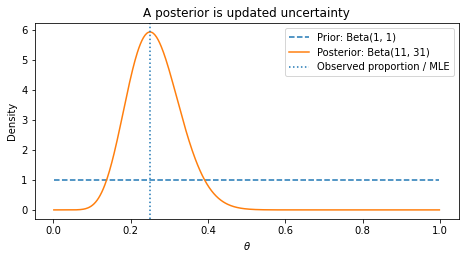

Posterior family: Beta(11, 31)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, norm, t as t_dist, probplot

rng = np.random.default_rng(2026)
alpha, prior_beta, n_bern, successes = 1, 1, 40, 10
post_a, post_b = alpha + successes, prior_beta + n_bern - successes
theta_grid = np.linspace(.001, .999, 500)

fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(theta_grid, beta.pdf(theta_grid, alpha, prior_beta), '--', label='Prior: Beta(1, 1)')
ax.plot(theta_grid, beta.pdf(theta_grid, post_a, post_b), label='Posterior: Beta(11, 31)')
ax.axvline(successes / n_bern, linestyle=':', label='Observed proportion / MLE')
ax.set(xlabel=r'$\theta$', ylabel='Density', title='A posterior is updated uncertainty')
ax.legend(); plt.show()
print(f'Posterior family: Beta({post_a}, {post_b})')

## 4. Normal likelihood and Normal prior: why completing the square works

Now observe $X_i\overset{\mathrm{iid}}\sim N(\mu,\sigma_0^2)$, where $\mu$ is unknown but $\sigma_0^2$ is known. Place the Normal prior $\mu\sim N(\mu_0,\tau_0^2)$ on the mean. As a function of $\mu$, the likelihood satisfies

$$
L(\mu;s)\propto\exp\left[-\frac{n}{2\sigma_0^2}(\mu-\bar x)^2\right].
$$

**Why does only $\bar x$ appear?** The identity $\sum_i(x_i-\mu)^2=\sum_i(x_i-\bar x)^2+n(\bar x-\mu)^2$ separates the part that depends on $\mu$ from the part that does not.

Multiplying prior and likelihood gives

$$
\pi(\mu\mid s)\propto
\exp\left[-\frac{(\mu-\mu_0)^2}{2\tau_0^2}-\frac{n(\mu-\bar x)^2}{2\sigma_0^2}\right].
$$

Take logarithms and expand *only the terms containing* $\mu$:

$$
\log\pi(\mu\mid s)=
-\frac12\left[
\underbrace{\left(\frac1{\tau_0^2}+\frac n{\sigma_0^2}\right)}_{A}\mu^2
-2\underbrace{\left(\frac{\mu_0}{\tau_0^2}+\frac{n\bar x}{\sigma_0^2}\right)}_{B}\mu
\right]+C,
$$

where $C$ does not depend on $\mu$. Complete the square:

$$
A\mu^2-2B\mu
=A\left(\mu-\frac BA\right)^2-\frac{B^2}{A}.
$$

The last term is constant in $\mu$. The posterior kernel therefore has the form $\exp[-A(\mu-B/A)^2/2]$, a Normal kernel with **mean** $B/A$ and **variance** $1/A$. Consequently,

$$
\boxed{\mu\mid s\sim N(\mu_n,\tau_n^2)},\quad
\boxed{\tau_n^2=\left(\frac1{\tau_0^2}+\frac n{\sigma_0^2}\right)^{-1}},\quad
\boxed{\mu_n=\tau_n^2\left(\frac{\mu_0}{\tau_0^2}+\frac{n\bar x}{\sigma_0^2}\right)}.
$$

This step illustrates a useful general technique: **identify an unknown density from its algebraic kernel**, then recover its normalizing factor from the known distribution family. No general principle requires the posterior and prior to have the same type; this happens here because the Normal prior is *conjugate* to the Normal location likelihood.

## 5. Precision-weighted updating and its interpretation

Define **precision** as reciprocal variance. The Normal posterior has

$$
\underbrace{\frac1{\tau_n^2}}_{\text{posterior precision}}=
\underbrace{\frac1{\tau_0^2}}_{\text{prior precision}}+
\underbrace{\frac n{\sigma_0^2}}_{\text{data precision}}.
$$

Its mean is the weighted average

$$
\mu_n=w_{\mathrm{prior}}\mu_0+w_{\mathrm{data}}\bar x,
\quad
w_{\mathrm{prior}}=\frac{1/\tau_0^2}{1/\tau_0^2+n/\sigma_0^2},
\quad w_{\mathrm{data}}=\frac{n/\sigma_0^2}{1/\tau_0^2+n/\sigma_0^2}.
$$

These weights sum to one: the more precise source of information receives the larger weight. More data also reduce the posterior variance. For the textbook values $\sigma_0^2=1$, $\mu_0=0$, $\tau_0^2=2$, $n=10$, and $\bar x=1.2$, the posterior is approximately $N(1.1429,0.09524)$. Its mean is close to $\bar x$ because the observed sample contributes much more precision than the prior.

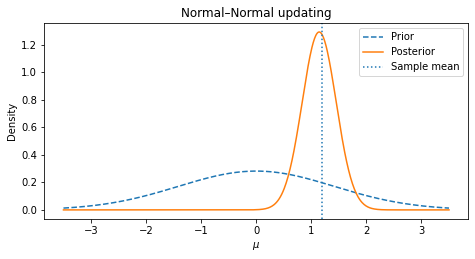

Posterior mean: 1.1429; posterior variance: 0.09524


In [2]:
mu0, tau02, sigma02, normal_n, xbar_normal = 0., 2., 1., 10, 1.2
posterior_var = 1 / (1 / tau02 + normal_n / sigma02)
posterior_mu = posterior_var * (mu0 / tau02 + normal_n * xbar_normal / sigma02)
mu_grid = np.linspace(-3.5, 3.5, 600)
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(mu_grid, norm.pdf(mu_grid, mu0, np.sqrt(tau02)), '--', label='Prior')
ax.plot(mu_grid, norm.pdf(mu_grid, posterior_mu, np.sqrt(posterior_var)), label='Posterior')
ax.axvline(xbar_normal, ls=':', label='Sample mean')
ax.set(xlabel=r'$\mu$', ylabel='Density', title='Normal–Normal updating')
ax.legend(); plt.show()
print(f'Posterior mean: {posterior_mu:.4f}; posterior variance: {posterior_var:.5f}')

## 6. When both the Normal mean and variance are unknown

The previous model assumed a known sampling variance. In the **location–scale Normal model** $X_i\sim N(\mu,\sigma^2)$, both parameters are unknown; hence Bayesian analysis requires a *joint* prior for $(\mu,\sigma^2)$.

The textbook constructs it hierarchically:

$$
\mu\mid\sigma^2\sim N(\mu_0,\tau_0^2\sigma^2),
\qquad \lambda=\frac1{\sigma^2}\sim\operatorname{Gamma}(\alpha_0,\beta_0),
$$

where the Gamma distribution is expressed with a **rate** parameter $\beta_0$. The joint prior factors as $\pi(\mu,\sigma^2)=\pi(\mu\mid\sigma^2)\pi(\sigma^2)$. Here $\pi(\sigma^2)$ is the **marginal prior for variance**; it is specified indirectly by assigning a Gamma distribution to the precision $\lambda$.

Normal and Gamma kernels give tractable posterior conditionals:

$$
\lambda\mid s\sim\operatorname{Gamma}\left(\alpha_0+\frac n2,\beta_s\right),\qquad
\mu\mid\sigma^2,s\sim N\left(\mu_s,\frac{\sigma^2}{n+1/\tau_0^2}\right).
$$

The explicit expression for $\beta_s$ is not needed to recognize the important structure: **draw the precision from its marginal posterior, then draw the mean conditional on that variance**. This will be useful when we reach posterior simulation. A prior on precision is a mathematical reparameterization, not a claim that variance is actually observed or known.

## 7. Using the posterior for a point estimate: mean, mode, and MAP

Obtaining a posterior distribution is not the end of an analysis. Suppose we want a **single numerical estimate** of a characteristic $\psi(\theta)$. Two natural—but different—summaries are:

$$
\boxed{\hat\psi_{\mathrm{mean}}=E[\psi(\theta)\mid s]},\qquad
\boxed{\hat\psi_{\mathrm{mode}}=\arg\max_u\,\pi_{\psi}(u\mid s)},
$$

where $\pi_\psi$ is the posterior density or probability function of $\psi$. For $\psi(\theta)=\theta$, the latter is the **maximum a posteriori (MAP)** estimate. These are **alternative estimates**, not successive stages of the same computation.

For our $\operatorname{Beta}(\alpha+k,\beta+n-k)$ posterior, the known Beta expectation immediately gives

$$
\boxed{E[\theta\mid s]=\frac{\alpha+k}{\alpha+\beta+n}}.
$$

To derive the **mode**, maximize the posterior kernel. Since the logarithm is strictly increasing, maximizing the kernel is equivalent to maximizing

$$
\ell_{\mathrm{post}}(\theta)=(\alpha+k-1)\log\theta+(\beta+n-k-1)\log(1-\theta).
$$

Differentiate and set the derivative to zero:

$$
\frac{\alpha+k-1}{\theta}-\frac{\beta+n-k-1}{1-\theta}=0
\quad\Longrightarrow\quad
\boxed{\hat\theta_{\mathrm{MAP}}=\frac{\alpha+k-1}{\alpha+\beta+n-2}},
$$

provided there is an interior mode (otherwise examine the boundaries). With the uniform $\operatorname{Beta}(1,1)$ prior and nondegenerate data, the MAP equals $k/n$, the **MLE**. Generally the MLE maximizes only $L(\theta;s)$, whereas MAP maximizes $\pi(\theta)L(\theta;s)$.

For our running data, posterior mean $11/42\approx0.2619$, MAP $10/40=0.25$, and MLE $0.25$. The distinction becomes more noticeable with skewed posteriors or more influential priors. The justification for preferring a particular estimate will become clearer with **loss functions** in Chapter 8.

## 8. Quantifying posterior uncertainty: variance and credible intervals

A point estimate alone conceals how concentrated the posterior is. The posterior variance is one description of this uncertainty; for $\theta\mid s\sim\operatorname{Beta}(a,b)$,

$$
\boxed{\operatorname{Var}(\theta\mid s)=\frac{ab}{(a+b)^2(a+b+1)}}.
$$

For fixed Beta prior parameters, it tends to zero as the number of observations grows. In the Normal location example, posterior variance is $(1/\tau_0^2+n/\sigma_0^2)^{-1}$: the prior variance shrinking to zero produces a concentrated posterior, while a very diffuse prior leads the posterior variance toward the sample-mean sampling variance $\sigma_0^2/n$.

A $\gamma$-**credible interval** $C(s)=[l(s),u(s)]$ satisfies

$$
\boxed{P\bigl(\psi(\theta)\in C(s)\mid s\bigr)\ge\gamma.}
$$

Here the probability refers to the **posterior uncertainty about the parameter given the observed data**. A frequentist confidence interval instead describes the repeated-sampling coverage of a procedure, so its probability statement refers to random future intervals, with the parameter fixed. Their numerical endpoints can be close, but the interpretations are different.

Two constructions from the textbook are an **equal-tailed interval** (cutting $\tfrac{1-\gamma}{2}$ from each tail) and a **highest posterior density (HPD) interval**, which contains high-density regions and, under appropriate conditions, minimizes interval length for the specified probability. HPD endpoints may require numerical methods; they need not agree with equal-tail endpoints for skewed distributions.

For the Beta(11,31) posterior, the equal-tailed credible interval is easily obtained from its quantile function; the code below reports it rather than performing another special-function derivation.

In [3]:
posterior_mean = post_a / (post_a + post_b)
posterior_mode = (post_a - 1) / (post_a + post_b - 2)
credible_limits = beta.ppf([.025, .975], post_a, post_b)
print(f'Posterior mean:       {posterior_mean:.4f}')
print(f'Posterior mode (MAP): {posterior_mode:.4f}')
print(f'Posterior variance:   {beta.var(post_a, post_b):.6f}')
print(f'95% equal-tail interval: [{credible_limits[0]:.4f}, {credible_limits[1]:.4f}]')

Posterior mean:       0.2619
Posterior mode (MAP): 0.2500
Posterior variance:   0.004496
95% equal-tail interval: [0.1422, 0.4030]


## 9. Posterior hypothesis probabilities and Bayes factors

The posterior can also measure support for a hypothesis. For a set $A\subseteq\Omega$, $P(\theta\in A\mid s)$ directly expresses its posterior probability. A subtlety arises with an **exact point hypothesis** $H_0:\theta=\theta_0$: under a purely continuous prior, its probability is zero and remains zero after conditioning.

To compare $H_0$ with a non-point alternative, the textbook considers a **mixture prior** that gives positive mass $p$ to $H_0$ and mass $1-p$ to an alternative prior. Let $m_0(s)$ and $m_1(s)$ be the marginal likelihoods (prior predictives) under the two hypotheses. Then

$$
P(H_0\mid s)=\frac{p\,m_0(s)}{p\,m_0(s)+(1-p)m_1(s)}.
$$

Define **odds** as probability divided by its complement. The **Bayes factor in favor of $H_0$** compares posterior odds with prior odds:

$$
\boxed{BF_{01}=\frac{P(H_0\mid s)/P(H_1\mid s)}{P(H_0)/P(H_1)}
=\frac{m_0(s)}{m_1(s)}},\quad
\boxed{\text{posterior odds}=BF_{01}\times\text{prior odds}}.
$$

For the textbook Normal-model numerical example, $BF_{01}\approx3.7878$. With equal prior odds ($p=1/2$), the resulting posterior probability of $H_0$ is about $3.7878/(1+3.7878)=0.7911$. This is **not a frequentist P-value**: it measures how the data modify relative support between two fully specified hypotheses/models, and it depends on the prior specification of the alternative.

## 10. Prediction: integrating over parameter uncertainty

Estimation asks about an unknown *parameter*. Prediction asks about an unobserved response $T$—possibly a future observation. Suppose the conditional model for it is $q_\theta(t\mid s)$. After observing $s$, we should not simply pretend the parameter is known at a point estimate; the **posterior predictive** averages over remaining parameter uncertainty:

$$
\boxed{q(t\mid s)=\int_\Omega q_\theta(t\mid s)\pi(\theta\mid s)\,d\theta}.
$$

This is the law of total probability applied to the posterior joint model. The $m(s)$ in the denominator of the posterior has already been absorbed into $\pi(\theta\mid s)$; no second normalization is needed here.

For our Bernoulli example, a future trial $X_{n+1}\mid\theta\sim\operatorname{Bernoulli}(\theta)$ is conditionally independent of the observed trials. Thus,

$$
P(X_{n+1}=1\mid s)=\int_0^1\theta\pi(\theta\mid s)\,d\theta
=E[\theta\mid s]=\frac{\alpha+k}{\alpha+\beta+n}.
$$

With Beta(11,31), the next success has predictive probability $11/42\approx0.2619$. A **predictive probability** is not itself a realized binary prediction: if a hard label is required, a separate decision rule (e.g. choose the more probable class) is needed. The predictive mean for a Bernoulli outcome can lie strictly between 0 and 1 even though a realized outcome must be 0 or 1.

## 11. Why Bayesian inference needs numerical computation

The conjugate examples yield closed-form posterior densities, means, and credible intervals. More complicated sampling models and priors often do not. Even a known posterior density can lead to integrals of the form

$$
E[w(\theta)\mid s]=\int_\Omega w(\theta)\pi(\theta\mid s)\,d\theta
$$

that are hard to evaluate analytically. What matters for inference is the ability to **calculate the desired posterior quantities**, not necessarily to write every marginal posterior density in closed form.

One alternative in textbook §7.3.1 is to approximate a well-behaved posterior near its mode $\hat\theta$. For scalar $\theta$, the local quadratic approximation to the **log posterior** gives a Normal approximation with variance

$$
\hat\sigma_{\mathrm{post}}^2\approx
\left[-\left.\frac{d^2}{d\theta^2}\log\bigl(L(\theta;s)\pi(\theta)\bigr)\right|_{\theta=\hat\theta}\right]^{-1},
$$

assuming negative curvature and appropriate regularity. This parallels the asymptotic likelihood approximations in Chapter 6. Here, however, our main computational focus is a second route: **sampling from the posterior**.

## 12. Posterior simulation: expectations as sample averages

Suppose we can draw independent values $\theta^{(1)},\ldots,\theta^{(N)}$ from the posterior $\pi(\theta\mid s)$. Replace an intractable expectation by the Monte Carlo average

$$
\boxed{\widehat{E[w(\theta)\mid s]}=\bar w_N=\frac1N\sum_{j=1}^N w(\theta^{(j)})}.
$$

This is the same principle encountered in the sampling-distributions part of the learning series, but there is an important change: the simulation draws are from the **posterior**, not from the original data-generating model. Here $n$ is the number of observed data points, while $N$ is the **number of Monte Carlo draws**.

Under an integrability condition, the law of large numbers gives $\bar w_N\to E[w(\theta)\mid s]$. If the posterior variance $\sigma_w^2=\operatorname{Var}(w(\theta)\mid s)$ is finite, the central limit theorem gives the approximate computational standard error

$$
\boxed{\operatorname{MCSE}(\bar w_N)\approx\frac{s_w}{\sqrt N}},\qquad
s_w^2=\frac1{N-1}\sum_{j=1}^N[w(\theta^{(j)})-\bar w_N]^2.
$$

For a posterior event $A$, take $w(\theta)=\mathbf 1_{\{\theta\in A\}}$. Then the average is simply the simulated fraction of draws inside $A$. Its variance can be estimated from the corresponding Bernoulli fraction.

**Two different uncertainties:** posterior variance quantifies uncertainty *about the parameter after seeing the data*. MCSE quantifies error from *numerically approximating* a posterior expectation using finitely many draws. Increasing $N$ reduces MCSE, but does not create more observed data or eliminate the posterior's uncertainty. A numerical mean may be meaningless if the posterior expectation does not exist; checking existence comes before simulation.

In [4]:
N_draws = 20_000
posterior_draws = rng.beta(post_a, post_b, size=N_draws)
indicator = (posterior_draws <= 0.30).astype(float)
estimate = indicator.mean()
mc_se = indicator.std(ddof=1) / np.sqrt(N_draws)
exact = beta.cdf(0.30, post_a, post_b)
print(f'P(theta <= 0.30 | data): MC {estimate:.4f}; exact {exact:.4f}')
print(f'Estimated Monte Carlo standard error: {mc_se:.5f}')
assert abs(estimate - exact) < 5 * mc_se

P(theta <= 0.30 | data): MC 0.7263; exact 0.7251
Estimated Monte Carlo standard error: 0.00315


## 13. Sampling a joint posterior and the purpose of Gibbs sampling

The location–scale Normal example supplies a useful case where we can **sample directly** even if the marginal distribution of a derived quantity is inconvenient. First sample precision $\lambda^{(j)}=1/(\sigma^2)^{(j)}$ from its marginal Gamma posterior. Set $(\sigma^2)^{(j)}=1/\lambda^{(j)}$, then sample $\mu^{(j)}$ from the conditional Normal posterior. Each pair is a draw from the joint posterior.

For any characteristic $\psi(\mu,\sigma^2)$, simply compute $\psi^{(j)}=\psi(\mu^{(j)},(\sigma^2)^{(j)})$. The resulting sample describes the **posterior of the derived quantity**, without requiring an analytic formula for its marginal density. The textbook uses $\psi=\sigma/\mu$ as an example and cautions that its posterior mean need not exist.

But **direct posterior sampling is not always available**. When the joint posterior is difficult to draw from, Gibbs sampling repeatedly updates individual parameters from their **conditional posterior distributions**, holding the others at their current values. Such draws are generally dependent, so the simple independent-draw MCSE formula above must not be used without accounting for dependence. The core lesson for now is conceptual: Monte Carlo approximates posterior integrals, while Gibbs sampling is a way to obtain posterior-oriented draws when direct sampling fails.

## 14. Choosing priors: conjugacy, elicitation, and hierarchical structure

A prior is not justified merely because it makes algebra easy. It should be reasonable relative to the question, the parameterization, and the available prior knowledge. The textbook develops several approaches, which are best understood as **different strategies for choosing a model component**:

| Strategy | Idea | Main qualification |
|:--|:--|:--|
| **Conjugate family** | Choose a family for which posterior and prior have the same form (Beta–Bernoulli, Normal–Normal, Dirichlet–Multinomial). | Computational convenience does not select the hyperparameters for us. |
| **Prior elicitation** | Specify hyperparameters through expert beliefs, probabilities, or quantiles. | Assumptions are explicit but may be subjective. |
| **Empirical Bayes** | Estimate prior hyperparameters by using the observed data, often through the marginal likelihood. | The same data help determine the prior; uncertainty in estimated hyperparameters may be understated. |
| **Hierarchical Bayes** | Put a **hyperprior** on the prior's hyperparameters and integrate over them. | The problem of selecting assumptions moves to the hyperprior level. |
| **Improper or diffuse prior** | Avoid strong finite concentration when little is known. | An improper prior is not a probability distribution; a **proper posterior** must be verified. |

For example, if $\pi_\lambda(\theta)$ is a prior indexed by hyperparameter $\lambda$ and $\omega(\lambda)$ its hyperprior, the marginal prior is

$$
\pi(\theta)=\int \pi_\lambda(\theta)\omega(\lambda)\,d\lambda.
$$

As this equation shows, an additional prior level changes the model but does not remove the need to check whether the assumptions are suitable. Chapter 9 will distinguish a sampling-model failure from **prior–data conflict**.

### Chapter 7 recap — rebuild the chain from one equation

$$
\underbrace{\pi(\theta)}_{\text{before data}}
\times\underbrace{L(\theta;s)}_{\text{what the data say}}
\quad\longrightarrow\quad
\underbrace{\pi(\theta\mid s)}_{\text{after data}}
\quad\longrightarrow\quad
\begin{cases}
\text{estimate / interval / hypothesis assessment},\\
\text{prediction via posterior averaging}.
\end{cases}
$$

| If you need to remember… | Recover this idea first |
|:--|:--|
| How a posterior is computed | $\pi(\theta\mid s)\propto\pi(\theta)L(\theta;s)$; $m(s)$ is the normalization. |
| Why Beta and Normal reappear | These are **conjugate** examples, not a general requirement. |
| Why posterior mean differs from MAP | Mean averages the distribution; mode finds its peak; MLE ignores the prior. |
| What a credible interval means | A posterior probability statement conditional on observed data. |
| What changes in prediction | Integrate the future-response model over the parameter posterior. |
| What posterior simulation solves | Replace intractable posterior integrals by averages of draws, checking existence and MC accuracy. |

**Retrieval checks:** Would a non-conjugate prior make Bayesian inference invalid? Why is the simulated proportion $\mathbf 1_{\{\theta<0.3\}}$ a posterior probability estimate? Which variance changes when we increase the number of *Monte Carlo* draws, rather than the number of *observations*?

The next chapter asks a different question: even with a posterior in hand, **what makes an estimator or decision preferable?**

# II. Optimal Inferences and Decision Theory
*Textbook: Chapter 8, with emphasis on the decision-theoretic ideas of §8.4.*

The preceding chapter offered posterior means and modes as plausible point estimates. But a distribution does not, by itself, tell us which single action we should take. To choose, we need to explain **what constitutes an error and how costly that error is**.

## 15. Actions, decision rules, loss, and risk

A decision problem has a parameter space $\Omega$, an **action space** $\mathcal A$ of choices, and a **loss function** $L(\theta,a)$ measuring the cost of choosing $a$ when $\theta$ is true. For point estimation of $\psi(\theta)$, the action is simply the estimate $a$ we report. For hypothesis testing, the actions might be to reject or not reject $H_0$.

A nonrandomized decision rule $d(s)$ assigns one action to each possible dataset $s$. The textbook also permits **randomized rules** $\delta(s,\cdot)$, probability distributions over actions after observing $s$.

What is meant by a *good* rule? Under sampling model $f_\theta$, the same rule can produce different losses on different datasets. Its **risk** averages these losses under repeated sampling, including any randomization of its actions:

$$
\boxed{R_\delta(\theta)=E_{s\sim f_\theta}\!\left[E_{a\sim\delta(s,\cdot)}L(\theta,a)\right]}. 
$$

Unlike a single loss on a single observation, risk is a **function of the true parameter**. Different rules may have smaller risk at different parameter values; therefore a uniformly best rule need not exist. Criteria such as minimizing worst-case risk or average risk under a prior help compare rules when their risk functions cross.

## 16. The loss function clarifies the choice of a point estimate

Return to the posterior of the quantity of interest $\psi=\psi(\theta)$ after observing $s$. Once the data are fixed, a Bayesian decision selects an action that minimizes **posterior expected loss**:

$$
\boxed{a^*(s)=\arg\min_a E[L(\theta,a)\mid s]}. 
$$

For **squared-error loss**, $L(\theta,a)=(\psi(\theta)-a)^2$. Write $m=E[\psi\mid s]$ and expand:

$$
\begin{aligned}
E[(\psi-a)^2\mid s]
&=E[(\psi-m+m-a)^2\mid s]\\
&=\operatorname{Var}(\psi\mid s)+(m-a)^2.
\end{aligned}
$$

The first term does not depend on $a$; the second is minimized at $a=m$. Therefore **posterior mean minimizes posterior squared-error loss** (when the relevant second moment exists). This explains why posterior expectation is already a *point estimator* rather than merely an intermediate calculation.

With **absolute-error loss**, the minimizing action is a **posterior median**. With 0–1 loss over a *discrete* action set, the mode is optimal. For continuous parameters, a density mode (MAP) is often intuitive but its decision-theoretic justification needs an appropriate loss formulation; a point has zero mass under a continuous posterior.

Thus there is no universally best point summary independently of the loss criterion. A skewed posterior may have different mean, median, and mode, and the preferred estimate can depend on the consequences of over- and underestimation.

## 17. MSE, the bias–variance decomposition, and inference priorities

A familiar frequentist performance measure is the **mean squared error** of an estimator $T(s)$ for a scalar parameter $\psi(\theta)$:

$$
\operatorname{MSE}_\theta(T)=E_\theta[(T-\psi(\theta))^2].
$$

Add and subtract $E_\theta[T]$ to obtain

$$
\boxed{\operatorname{MSE}_\theta(T)=
\operatorname{Var}_\theta(T)+\bigl(E_\theta[T]-\psi(\theta)\bigr)^2}.
$$

Variance quantifies how much the estimator changes across repeated datasets; squared bias quantifies its systematic shift from the parameter. An estimator can have low variance and substantial bias, or the reverse. This decomposition motivates the search for good inference procedures but, by itself, does **not** identify one method that is optimal for every distribution and sample size.

A key distinction: **frequentist risk/MSE** averages over data generated under a fixed parameter; **posterior expected loss** averages over a parameter distribution *after conditioning on the observed data*. They evaluate different probability spaces, even when the loss has the same algebraic form.

### Chapter 8 recap — the evaluation criterion matters

| Question | Object |
|:--|:--|
| What may the statistician choose? | Action $a\in\mathcal A$ |
| What does a mistake cost? | Loss $L(\theta,a)$ |
| How is an action selected from data? | Decision rule $d(s)$ or randomized rule $\delta(s,\cdot)$ |
| How well does that rule work across datasets? | Risk $R_\delta(\theta)$ |
| How is a Bayesian action chosen after observing $s$? | Minimize $E[L(\theta,a)\mid s]$ |

**Retrieve the central idea:** the posterior mean is not automatically best because it is a mean; it is optimal for **posterior squared-error loss**. Chapter 9 now turns to a prior question: are the assumptions underlying such inferences actually plausible?

# III. Model Checking
*Textbook: Chapter 9.*

Likelihood inference, Bayesian inference, and decision theory can all be mathematically correct **conditional on an assumed model**. They need not be valid descriptions of the real data-generating situation. Model checking therefore asks whether the actual observations are plausible under the assumptions made.

## 18. What needs checking, and why a small P-value is not the whole story

A sampling model is a set of candidate distributions $\{f_\theta:\theta\in\Omega\}$. Its fit must be assessed before treating its estimates, P-values, or intervals as reliable. A Bayesian analysis also specifies a prior, so there are **two possible sources** of trouble: the sampling model itself, and the prior's compatibility with observations.

A model is rarely proved correct; at best, observed data fail to expose serious discrepancies. This does not mean the model is literally true. It means its assumptions may be useful enough for the question being asked.

An important distinction from Chapter 6 is between **statistical significance** and **practical significance**. With a huge sample, even a tiny deviation from an ideal model may yield a small model-checking P-value. Whether that deviation matters for prediction or interpretation depends on its **size and consequences**, not solely on a conventional significance threshold.

## 19. Discrepancy statistics, ancillary quantities, and residuals

A **discrepancy statistic** $D(s)$ measures an aspect of the data that would be unusual if the assumed model were correct. A model-checking test asks whether the observed $D(s)$ is surprising under its reference distribution. Depending on the statistic, unusually **large** or **small** values (or both) can be concerning.

The difficulty is that the distribution of $D(s)$ can depend on the unknown parameter $\theta$. The textbook describes two ways to obtain a usable reference distribution:

1. Choose an **ancillary statistic**, whose distribution does **not** depend on $\theta$.
2. Condition on a **sufficient statistic** $T(s)$; under the model, the conditional distribution of the remaining data given $T$ does not depend on $\theta$.

An ancillary statistic need not be useful for checking: a constant is ancillary but detects nothing. The statistic must be sensitive to meaningful departures from the model.

**Residuals** are particularly useful. In a Normal location model with unknown mean $\mu$, the sample mean $\bar X$ summarizes the fitted location. The residuals

$$
\boxed{r_i=x_i-\bar x}
$$

record deviations from that fitted mean. Under the location Normal model with known variance $\sigma_0^2$, each $r_i$ has mean zero and variance $\sigma_0^2(1-1/n)$; standardized residuals can be checked for patterns or unexpected tails. Residuals share the constraint $\sum_i r_i=0$, so they are **not exactly independent**, although dependence is weak in many large-sample settings.

For categorical count data, the chi-squared goodness-of-fit statistic plays a similar role by comparing observed and expected cell counts. Its reference distribution depends on how parameters and degrees of freedom are estimated; it is not a universal numerical measure of goodness-of-fit.

## 20. Reading residual plots and Normal probability plots

A residual-versus-observation or residual-versus-predictor plot is meant to reveal **structure that the model failed to capture**. Patterns, changing spread, skewness, or outlying residuals can suggest inappropriate assumptions. But apparent patterns can also occur by chance, especially with small samples.

The **Normal probability plot** (often called a Q–Q plot) compares ordered observations or residuals with theoretical Normal quantiles. For $n$ observations, a rough reference uses Normal scores $\Phi^{-1}(i/(n+1))$ for order $i$. A roughly straight pattern is consistent with a Normal-shaped distribution; clear systematic curvature can indicate skewness or heavy tails.

The textbook contrasts observations $Y=\exp(X)$ for $X\sim N(0,1)$ with the transformed values $\log Y=X$. The raw positive observations are skewed and produce a curved Normal probability plot; their logarithms follow a Normal distribution and give an approximately linear plot. This is a **model-specific demonstration of a useful transformation**, not a rule to log-transform every positive variable.

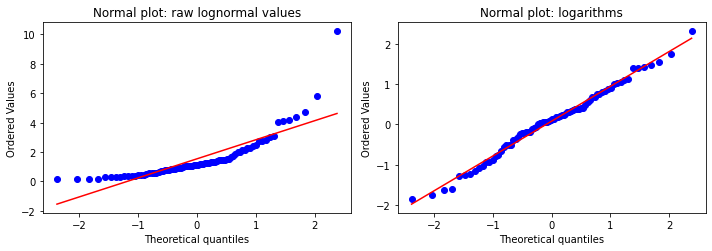

In [5]:
# Simulation illustrating the transformation discussed in textbook §9.1.4.
rng_check = np.random.default_rng(109)
y_skew = np.exp(rng_check.normal(size=80))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
probplot(y_skew, dist='norm', plot=axes[0])
axes[0].set_title('Normal plot: raw lognormal values')
probplot(np.log(y_skew), dist='norm', plot=axes[1])
axes[1].set_title('Normal plot: logarithms')
plt.tight_layout(); plt.show()

## 21. Prediction and cross-validation: checking beyond fitted data

A model may match the observations used for fitting but predict new observations poorly. This is why the textbook presents **out-of-sample prediction** as a particularly compelling form of checking. If genuinely new measurements are unavailable, we can reserve some of the observed data for assessment.

In a simple **holdout validation**, split the data into a training portion $T$ and a validation portion $V$. Fit the model using $T$ only, then compare its predictions with the values held out in $V$. The validation measurements must not affect the fitting of that particular model, or the check loses its independence from training.

One split can be unstable. **Cross-validation** repeats the fitting-and-assessment process over multiple splits or folds. The textbook introduces the principle rather than developing full algorithms. The conceptual distinction matters: *training fit* measures agreement with data used in estimating parameters, whereas *validation performance* investigates how predictions transfer to unseen cases.

The small simulation below expands the textbook's holdout idea using models of different polynomial degrees. It is a **supplementary demonstration**, not a reconstruction of a textbook exercise: higher flexibility can reduce training error without necessarily improving validation error.

In [6]:
# Supplementary holdout illustration of the textbook's cross-validation principle.
rng_cv = np.random.default_rng(120)
x_train = rng_cv.uniform(-1.5, 1.5, 24)
y_train = 1 + .3*x_train - 1.7*x_train**2 + rng_cv.normal(0, .45, 24)
x_valid = rng_cv.uniform(-1.5, 1.5, 200)
y_valid = 1 + .3*x_valid - 1.7*x_valid**2 + rng_cv.normal(0, .45, 200)
print('Degree | train MSE | holdout MSE')
for degree in (1, 2, 5, 12):
    design_train = np.polynomial.polynomial.polyvander(x_train, degree)
    design_valid = np.polynomial.polynomial.polyvander(x_valid, degree)
    coef = np.linalg.lstsq(design_train, y_train, rcond=None)[0]
    print(f'{degree:6} | {np.mean((y_train-design_train@coef)**2):9.4f} | '
          f'{np.mean((y_valid-design_valid@coef)**2):11.4f}')

Degree | train MSE | holdout MSE
     1 |    1.6679 |      1.3942
     2 |    0.1103 |      0.2222
     5 |    0.0945 |      0.2484
    12 |    0.0379 |     36.4081


**Interpretation.** The degree-12 polynomial fits the *training* sample extremely well, yet its holdout error is much larger than that of the degree-2 model. The numerical values are specific to this simulated split; the general lesson is that additional flexibility can improve training fit without improving prediction.

## 22. When a model fails, what can be changed?

A surprising diagnostic should prompt an investigation, not automatic abandonment of every result. We might change the assumed distributional family, transform the response, add relevant structure, or reassess the data collection process. The revised model needs **fresh checking**, particularly for prediction.

Textbook examples include logarithmic transformations for strictly positive data and square-root transformations for certain count data. Transformations can change the scale on which a simple distributional relationship is plausible. However, repeatedly trying arbitrary transformations until one passes a diagnostic is a form of data-dependent selection that can exaggerate the apparent fit.

In practice the adequacy question is **purpose dependent**: a model can deviate from exact assumptions yet still predict within a tolerable error range. Conversely, an excellent-looking residual plot cannot establish accuracy on unseen data.

## 23. Sampling-model failure versus prior–data conflict

A Bayesian model assigns the **prior predictive** distribution

$$
m(s)=\int f_\theta(s)\pi(\theta)\,d\theta.
$$

If observed data are surprising under $m$, one explanation is a wrong sampling model; another is that the model contains a plausible distribution but the **prior puts too little probability near it**. These are logically different defects.

The textbook supplies a useful finite example. Suppose $\theta$ indexes two Bernoulli models: $P(Y=1\mid\theta=1)=0.1$ and $P(Y=1\mid\theta=2)=0.9$. We observe twenty successes. This dataset is perfectly plausible under the second model, because $0.9^{20}\approx0.1216$. But put prior masses $P(\theta=1)=0.9999$ and $P(\theta=2)=0.0001$. Then the prior predictive probability of this **particular ordered outcome** is

$$
m(s)=0.9999(0.1)^{20}+0.0001(0.9)^{20}\approx1.216\times10^{-5}.
$$

The **sampling family includes a plausible explanation**; the **prior strongly disfavors it**. That is a prior–data conflict. The textbook recommends first checking the sampling model and then assessing prior–data conflict, commonly by inspecting a sufficient statistic under its prior predictive distribution.

With enough informative data and suitable regularity and prior support, posterior inference may overcome a poor initial prior. It is still important to identify the conflict, especially when data are limited.

## 24. Multiple model checks and the risk of finding patterns by chance

Every informal diagnostic or formal test has sampling variability. Repeatedly searching for a statistic that looks unusually discrepant can find apparent problems **even when the assumed model is adequate**. The issue resembles multiple comparisons or selective testing.

The textbook's practical advice is to **choose a limited set of substantively relevant model checks before examining the data** rather than continue testing until something fails. This does not prohibit exploratory diagnostics, but exploratory discoveries should be described honestly and, where possible, checked on new data. The focus is on finding consequential failures without confusing ordinary chance fluctuations for decisive evidence.

### Chapter 9 recap — check assumptions before trusting inference

| Diagnostic question | Main idea |
|:--|:--|
| Does the sampling family plausibly generate the data? | Examine discrepancies, residuals, probability plots, and relevant tests. |
| Are assumptions accurate enough for the use case? | Consider the **size and practical effect** of departures, not P-values alone. |
| Does the fitted model predict genuinely held-out data? | Use validation or cross-validation rather than training agreement alone. |
| Is the model family plausible but the prior poorly aligned with data? | Check for **prior–data conflict** using the prior predictive distribution. |
| Are we searching too many diagnostics after seeing results? | Recognize selection effects; specify a small set of relevant checks in advance. |

**Retrieval checks:** Does a straight Q–Q plot prove the Normal model? Why can a prior predictive check fail even when at least one distribution within the sampling model fits well? What does training error fail to measure?

Having learned to check assumed distributions, we turn to models in which one variable is used to understand or predict another.

# IV. Relationships Among Variables
*Textbook: Chapter 10.*

Until now, the models mostly described the distribution of one type of observation. We next study how the **conditional distribution of a response** changes with explanatory variables. The chapter starts with the broad idea of a relationship, then treats categorical variables, least squares, linear regression, group comparisons, and finally a binary-response model with a nonlinear link.

## 25. Related variables and conditional distributions

A relationship is broader than a deterministic formula such as $Y=a+bX$. Two individuals with the same predictor value can have different responses; what may change with the predictor is the entire conditional distribution.

The textbook calls $X$ and $Y$ **related** if the distribution of $Y\mid X=x$ changes as $x$ varies. If the conditional distribution does *not* depend on $x$, then $X$ and $Y$ are **independent** (assuming the usual meaning of the conditional distribution). The amount of change indicates the **strength** of the relationship: a statistically detectable difference may still be too small to matter in an application.

In prediction problems, $Y$ is the **response variable** and $X$ a **predictor**. With several predictors $X_1,\ldots,X_k$, the full relationship is described by the family

$$
p(y\mid X_1=x_1,\ldots,X_k=x_k).
$$

A **regression assumption** simplifies this family: as the predictors vary, the conditional distributions retain their shape and can change only through the **conditional mean**. Thus, under that assumption, understanding the relationship reduces to understanding the function

$$
\boxed{g(x_1,\ldots,x_k)=E[Y\mid X_1=x_1,\ldots,X_k=x_k]}. 
$$

Without this assumption, equal conditional means need **not** imply independence: the variance or distribution shape could depend on $x$ even when the mean stays constant. In a simple Normal linear-regression model, the stronger assumption is

$$
Y\mid X=x\sim N(\beta_1+\beta_2x,\sigma^2).
$$

That statement specifies a conditional **distribution**, whereas $E[Y\mid X=x]=\beta_1+\beta_2x$ specifies only its **mean**. This distinction is essential when we later calculate confidence intervals and check residuals.

## 26. Association is not automatically cause and effect

A change in $p(Y\mid X=x)$ establishes a statistical association, not necessarily that intervening on $X$ would change $Y$. A **confounder** $Z$ may be related to both variables, making their observed association misleading.

The textbook discusses conditioning on an additional variable $Z$ and the importance of experiments in which predictor values can be assigned. In observational data, comparisons such as $p(Y\mid X=x,Z=z)$ help describe associations within groups, but **conditioning is not automatically enough to establish causality**: hidden confounders and selection effects can remain.

Randomly assigning treatments or predictor settings can protect comparisons against many confounding mechanisms when an experiment is appropriately designed and executed. This discussion prepares an important distinction for later machine-learning practice: a model that predicts well has not necessarily uncovered a causal mechanism.

## 27. Two categorical variables: cell probabilities and independence

Suppose categorical $X$ takes values $1,\ldots,a$ and categorical $Y$ takes values $1,\ldots,b$. When their values are jointly sampled, let

$$
\theta_{ij}=P(X=i,Y=j),\qquad f_{ij}=\#\{r:(x_r,y_r)=(i,j)\}.
$$

The multinomial-style likelihood has kernel

$$
L(\theta;s)\propto\prod_{i=1}^a\prod_{j=1}^b\theta_{ij}^{f_{ij}},\qquad
\hat\theta_{ij}=\frac{f_{ij}}n.
$$

To examine whether $X$ and $Y$ are related, compare the **conditional cell probabilities**

$$
P(Y=j\mid X=i)=\frac{\theta_{ij}}{\theta_{i\cdot}},\qquad
\theta_{i\cdot}=\sum_j\theta_{ij}.
$$

If these conditional distributions are identical across the levels of $X$, the variables are independent. A chi-squared statistic compares observed cell counts with counts expected under independence; it provides evidence *about the relationship* when the relevant sampling assumptions and reference approximation hold.

The textbook distinguishes a **random predictor** (levels $X=i$ arise from sampling) from a **deterministic/assigned predictor** (numbers sampled at each level are fixed by design). The corresponding likelihoods differ in their treatment of $X$, although both analyze variation in $Y\mid X$.

For Bayesian analysis, a Dirichlet prior is conjugate to these multinomial likelihoods: each posterior concentration parameter equals its prior value plus the corresponding observed count. This is the multivariate analogue of Beta–Bernoulli updating; the detailed contingency-table tests are not needed for the regression calculations that follow.

## 28. Least squares begins with estimating a mean

Suppose a real-valued response has observations $y_1,\ldots,y_n$, and we wish to estimate its population mean by a permissible value $t$. **The least-squares principle** selects the value minimizing

$$
S(t)=\sum_{i=1}^n(y_i-t)^2.
$$

Insert $y_i-t=(y_i-\bar y)+(\bar y-t)$ and expand. The cross term disappears because $\sum_i(y_i-\bar y)=0$:

$$
\begin{aligned}
S(t)&=\sum_i(y_i-\bar y)^2
+2(\bar y-t)\sum_i(y_i-\bar y)
+n(\bar y-t)^2\\
&=\underbrace{\sum_i(y_i-\bar y)^2}_{\text{fixed for the data}}+n(\bar y-t)^2.
\end{aligned}
$$

Therefore, if the parameter space permits it, the unique minimizing value is **$t=\bar y$**. If only certain mean values are allowed, least squares chooses the allowed value closest to $\bar y$.

What was assumed? Nothing about the shape of the response distribution is needed to define and solve this squared-distance optimization. A Normal distribution makes least squares **equivalent to maximum likelihood for Normal location parameters** because its negative log-likelihood is proportional to a sum of squared deviations. That equivalence depends on the model; it is not true for arbitrary likelihoods.

Regression extends the same principle from choosing one constant mean to choosing a **function of the predictor**.

## 29. Simple linear regression: deriving the fitted line

Assume the response's conditional mean is linear in a quantitative predictor:

$$
\boxed{E[Y\mid X=x]=\beta_1+\beta_2x},
$$

with intercept $\beta_1$ and slope $\beta_2$. For observed pairs $(x_i,y_i)$, choose estimates $b_1,b_2$ to minimize the sum of squared **vertical** deviations

$$
S(b_1,b_2)=\sum_{i=1}^n(y_i-b_1-b_2x_i)^2.
$$

Differentiate with respect to each coefficient, set the derivatives to zero, and obtain the **normal equations**:

$$
\sum_i(y_i-b_1-b_2x_i)=0,
\qquad \sum_i x_i(y_i-b_1-b_2x_i)=0.
$$

The first equation yields $b_1=\bar y-b_2\bar x$. Substitute it into the second; after centering the data, we obtain

$$
\boxed{b_2=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2}},\qquad
\boxed{b_1=\bar y-b_2\bar x}.
$$

These formulas require variation in $x$: if all predictors are equal, $\sum_i(x_i-\bar x)^2=0$ and the slope cannot be uniquely determined. The fitted response at each observed predictor is

$$
\hat y_i=b_1+b_2x_i,\qquad r_i=y_i-\hat y_i.
$$

The second expression is the **residual**: the observed vertical deviation from the fitted line, not a measure of sampling uncertainty for the coefficient estimate.

**Running regression example (textbook Example 10.3.3).** The following code uses the ten observed pairs from the text. We will reuse the same fit for standard errors, ANOVA decomposition, and residual diagnostics.

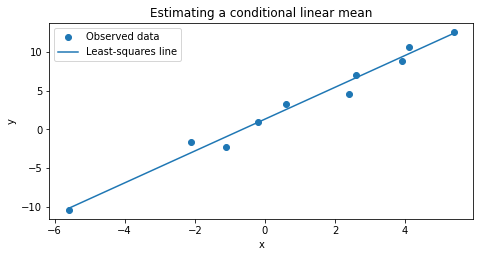

Intercept and slope: [1.3309 2.0591]
Sum of squared residuals: 8.4564


In [7]:
# Textbook Example 10.3.3: same data throughout the simple-regression sections.
x_reg = np.array([3.9, 2.6, 2.4, 4.1, -.2, 5.4, .6, -5.6, -1.1, -2.1])
y_reg = np.array([8.9, 7.1, 4.6, 10.7, 1.0, 12.6, 3.3, -10.4, -2.3, -1.6])
n_reg = len(x_reg)
X_reg = np.column_stack([np.ones(n_reg), x_reg])  # (n, p) = (10, 2)
b_hat = np.linalg.lstsq(X_reg, y_reg, rcond=None)[0]   # (2,)
y_hat = X_reg @ b_hat                                # (10,)
residuals = y_reg - y_hat
order = np.argsort(x_reg)
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.scatter(x_reg, y_reg, label='Observed data')
ax.plot(x_reg[order], y_hat[order], label='Least-squares line')
ax.set(xlabel='x', ylabel='y', title='Estimating a conditional linear mean')
ax.legend(); plt.show()
print('Intercept and slope:', np.round(b_hat, 4))
print('Sum of squared residuals:', np.sum(residuals**2).round(4))
assert np.allclose(residuals.sum(), 0, atol=1e-10)

## 30. What standard errors add to simple regression

Least squares produces a fitted line from the observed sample. To make inference about its **population coefficients** we must also consider how the estimates would vary if new data were sampled under the assumed model.

For independently observed responses with the correct linear conditional mean and constant conditional variance $\operatorname{Var}(Y\mid X=x)=\sigma^2$, the least-squares estimates are unbiased (conditional on the observed predictor values), and

$$
\begin{aligned}
\operatorname{Var}(B_2\mid x)&=\frac{\sigma^2}{S_{xx}},\\
\operatorname{Var}(B_1\mid x)&=\sigma^2\left(\frac1n+\frac{\bar x^2}{S_{xx}}\right),
\qquad S_{xx}=\sum_i(x_i-\bar x)^2.
\end{aligned}
$$

When the common conditional variance $\sigma^2$ is unknown, estimate it using the fitted residuals:

$$
\boxed{s^2=\frac{1}{n-2}\sum_i(y_i-b_1-b_2x_i)^2}.
$$

The denominator is $n-2$, not $n$, because two fitted coefficients use two degrees of freedom. Substituting $s^2$ into the sampling variances gives estimated **standard errors** $\mathrm{SE}(b_j)$; these quantify *estimator variability*, not the scatter of individual responses.

**Prediction and extrapolation:** The estimated conditional mean at $x_0$ is $b_1+b_2x_0$, with estimated variance

$$
\widehat{\operatorname{Var}}(B_1+B_2x_0\mid x)=s^2\left[\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}}\right].
$$

This measures uncertainty about the **mean response at $x_0$**. A new individual response also has its own variability around that mean, so its prediction interval is wider under the Normal model. Prediction outside the observed predictor range (**extrapolation**) is particularly fragile: the expression above grows as $x_0$ moves away from $\bar x$, and the linear-model assumption may fail beyond the observed range.

In [8]:
# Estimated sampling uncertainty for the *same* fitted line.
_, p_reg = X_reg.shape
s2_reg = np.sum(residuals**2) / (n_reg-p_reg)
cov_b = s2_reg * np.linalg.inv(X_reg.T @ X_reg)
se_b = np.sqrt(np.diag(cov_b))
t_crit = t_dist.ppf(.975, n_reg-p_reg)
ci_slope = b_hat[1] + np.array([-1., 1.])*t_crit*se_b[1]
x0 = 2.0
v0 = np.array([1., x0])
mean_prediction = v0 @ b_hat
se_mean_prediction = np.sqrt(v0 @ cov_b @ v0)
print(f'Residual variance estimate: {s2_reg:.4f}')
print('Coefficient standard errors:', np.round(se_b, 4))
print('95% slope interval (Normal assumption):', np.round(ci_slope, 4))
print(f'Estimated mean at x=2: {mean_prediction:.4f}; SE of fitted mean: {se_mean_prediction:.4f}')

Residual variance estimate: 1.0570
Coefficient standard errors: [0.3408 0.1023]
95% slope interval (Normal assumption): [1.8232 2.2949]
Estimated mean at x=2: 5.4491; SE of fitted mean: 0.3408


## 31. ANOVA decomposition, the F-statistic, and $R^2$

How much of the observed variation in $Y$ is represented by the fitted linear relationship? With an intercept, the least-squares fitted values and residuals satisfy an exact algebraic decomposition:

$$
\underbrace{\sum_i(y_i-\bar y)^2}_{\text{total variation: TSS}}
=\underbrace{\sum_i(\hat y_i-\bar y)^2}_{\text{regression / explained SS}}
+\underbrace{\sum_i(y_i-\hat y_i)^2}_{\text{residual / error SS}}.
$$

The textbook names **regression sum of squares** *RSS* and **error sum of squares** *ESS*. Some modern libraries call the *residual* sum of squares RSS, so **the explicit definitions matter more than the abbreviation**.

A standard descriptive ratio is the **coefficient of determination**:

$$
\boxed{R^2=\frac{\text{regression SS}}{\text{TSS}}=1-\frac{\text{error SS}}{\text{TSS}}},
\quad 0\le R^2\le1
$$

for ordinary least squares **with an intercept**, on the training observations. It measures the proportion of observed response variation accounted for by the fitted line in this sample; it does **not prove causal influence** or guarantee out-of-sample predictive accuracy. In simple linear regression with an intercept, $R^2$ equals the **square of the sample correlation** $r_{xy}$.

For testing $H_0:\beta_2=0$ under the **Normal linear-regression model**, the *F-statistic* compares the explained variation per regression degree of freedom to the estimated residual variation:

$$
\boxed{F=\frac{\text{regression SS}/1}{\text{error SS}/(n-2)}}
\overset{H_0}{\sim}F(1,n-2).
$$

Large values provide evidence against a zero slope. In this one-predictor setting the corresponding two-sided slope $t$-test gives the same conclusion because $F=t^2$. Exact $t$ and $F$ reference distributions require the additional Normal sampling assumptions; the sum-of-squares identity itself does not.

In [9]:
tss_reg = np.sum((y_reg - y_reg.mean())**2)
model_ss = np.sum((y_hat - y_reg.mean())**2)
error_ss = np.sum(residuals**2)
r2 = 1 - error_ss/tss_reg
f_obs = (model_ss / 1) / (error_ss / (n_reg-2))
print(f'TSS = {tss_reg:.3f}; regression SS = {model_ss:.3f}; error SS = {error_ss:.3f}')
print(f'R² = {r2:.4f}; correlation² = {np.corrcoef(x_reg,y_reg)[0,1]**2:.4f}')
print(f'F statistic for zero slope = {f_obs:.2f}')
assert np.isclose(tss_reg, model_ss + error_ss)

TSS = 437.009; regression SS = 428.553; error SS = 8.456
R² = 0.9806; correlation² = 0.9806
F statistic for zero slope = 405.42


**Interpretation.** In this calculation, the unrounded $s^2$ and sums of squares give $F\approx405.42$, while the textbook reports approximately $404.29$ after using the **rounded** values $428.55/1.06$. The difference is arithmetic rounding, not a disagreement about the test. The close equality $R^2=r_{xy}^2$ also depends on the *simple* linear model including an intercept.

## 32. Regression residuals bring us back to model checking

The slope estimate, its confidence interval, and the F-test depend on the regression assumptions. Rather than trusting a line simply because $R^2$ is large, inspect what it has **failed to explain**.

For simple regression, the fitted residual at $x_i$ is $r_i=y_i-b_1-b_2x_i$. Their variances can differ because observations at high-leverage predictor values influence their own fitted values strongly. The textbook therefore introduces standardized residuals of the form

$$
\boxed{r_i^*=\frac{y_i-b_1-b_2x_i}{s\sqrt{1-h_{ii}}}},\quad
h_{ii}=\frac1n+\frac{(x_i-\bar x)^2}{S_{xx}}.
$$

A residual plot against $x_i$ should have no systematic location pattern or changing spread when the model is suitable. A Normal probability plot checks whether the shape is compatible with the assumed Normal response errors. These checks may miss problems and do not replace held-out prediction assessment.

A useful conceptual distinction is that **residuals concern observed responses relative to fitted values**, whereas **coefficient standard errors concern how parameter estimates would vary between samples**. Their formulas can involve the same $s^2$, but they answer different questions.

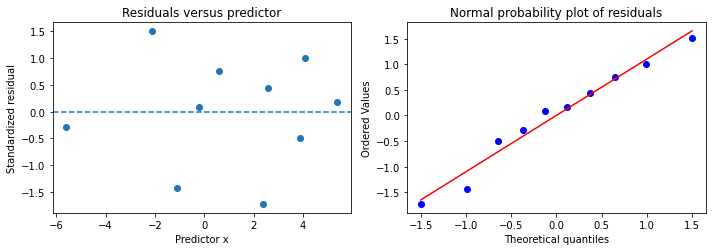

In [10]:
# Diagnostics on the *same* ten-point regression example.
hat_diag = np.sum(X_reg * (X_reg @ np.linalg.inv(X_reg.T @ X_reg)), axis=1)
standardized_residuals = residuals / (np.sqrt(s2_reg) * np.sqrt(1-hat_diag))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(x_reg, standardized_residuals)
axes[0].axhline(0, linestyle='--')
axes[0].set(xlabel='Predictor x', ylabel='Standardized residual', title='Residuals versus predictor')
probplot(standardized_residuals, dist='norm', plot=axes[1])
axes[1].set_title('Normal probability plot of residuals')
plt.tight_layout(); plt.show()

## 33. Multiple regression: the least-squares problem in matrix notation

With several quantitative predictors, the conditional mean remains **linear in the unknown coefficients**, even though there are now several columns of predictors. For $n$ observed responses and $p$ coefficients, collect the predictors into the **design matrix** $V\in\mathbb R^{n\times p}$, the responses into $y\in\mathbb R^n$, and coefficients into $\beta\in\mathbb R^p$:

$$
\underbrace{E[Y\mid V]}_{n\times1}=\underbrace{V}_{n\times p}\underbrace{\beta}_{p\times1}.
$$

For an intercept, the first column of $V$ is all ones. Least squares selects

$$
\boxed{b=\arg\min_{\beta\in\mathbb R^p}\|y-V\beta\|_2^2},
\qquad \|y-V\beta\|_2^2=(y-V\beta)^T(y-V\beta).
$$

Expand the scalar objective:

$$
S(\beta)=y^Ty-2\beta^TV^Ty+\beta^TV^TV\beta.
$$

Differentiation gives $\nabla_\beta S=-2V^Ty+2V^TV\beta$. Setting the gradient to zero produces the **normal equations**

$$
V^TVb=V^Ty.
$$

If the columns of $V$ are linearly independent (i.e. $\operatorname{rank}(V)=p$, requiring $n\ge p$), then $V^TV$ is invertible and the unique least-squares solution is

$$
\boxed{b=(V^TV)^{-1}V^Ty},\qquad b\in\mathbb R^p.
$$

This is the textbook's central formula for multiple regression. In numerical computation, explicit matrix inversion is usually avoided in favor of stable least-squares solvers such as QR or SVD. That computational recommendation is additional implementation context; it does not change the mathematical result.

In [11]:
# The simple-regression example is also a matrix least-squares problem.
manual_b = np.linalg.solve(X_reg.T @ X_reg, X_reg.T @ y_reg)
solver_b = np.linalg.lstsq(X_reg, y_reg, rcond=None)[0]
print('Shapes: V', X_reg.shape, 'y', y_reg.shape, 'beta', manual_b.shape)
print('Normal equations:', np.round(manual_b, 5))
print('Numerical least squares:', np.round(solver_b, 5))
assert np.allclose(manual_b, solver_b)

Shapes: V (10, 2) y (10,) beta (2,)
Normal equations: [1.33094 2.05906]
Numerical least squares: [1.33094 2.05906]


## 34. Fitted values, residual vectors, and an orthogonality condition

Once coefficients $b$ are fitted, the vector of predictions and the vector of residuals are

$$
\boxed{\hat y=Vb}\in\mathbb R^n,\qquad
\boxed{r=y-Vb}\in\mathbb R^n.
$$

A useful consequence of the normal equations is

$$
\boxed{V^Tr=V^T(y-Vb)=0}.
$$

Thus the residual vector is **orthogonal to every column of the design matrix**. This is the geometric meaning of least squares: the fitted response vector is the point in the column space of $V$ closest to the observed $y$ in Euclidean distance. Orthogonality also explains why the residuals sum to zero when $V$ contains an intercept column.

This is a geometric interpretation of the textbook's matrix formula, included here to make the algebra easier to retain. It requires no new probability distribution; it is a property of the optimization problem itself. The relationship between regression and linear algebra will be especially useful when moving to optimization methods later.

## 35. Uncertainty of multiple-regression coefficients and predictions

The matrix formula supplies the estimate, but its **sampling variability** requires a model for the response observations. With independent responses, correct linear conditional means, common conditional variance $\sigma^2$, and full column rank,

$$
E[B\mid V]=\beta,
\qquad
\boxed{\operatorname{Cov}(B\mid V)=\sigma^2(V^TV)^{-1}},
$$

where $B$ is the random least-squares estimator before the data are observed. This matrix describes both individual coefficient variances (diagonal entries) and pairwise covariances (off-diagonal entries).

Estimate $\sigma^2$ by dividing squared residuals by the residual degrees of freedom:

$$
\boxed{s^2=\frac{\|y-Vb\|_2^2}{n-p}},\qquad n>p.
$$

For a new predictor vector $x_0\in\mathbb R^p$, the estimated conditional mean is $x_0^Tb$, with estimated sampling variance

$$
\boxed{\widehat{\operatorname{Var}}(x_0^TB\mid V)=s^2x_0^T(V^TV)^{-1}x_0}.
$$

The dimensions check: $x_0^T$ has shape $1\times p$, $(V^TV)^{-1}$ has shape $p\times p$, and $x_0$ has shape $p\times1$; the result is one scalar variance.

Near-collinearity among predictor columns makes $V^TV$ poorly conditioned, potentially inflating the uncertainty of individual coefficients. It is possible for the fitted response vector to be quite stable while individual coefficient estimates are difficult to interpret.

## 36. What the Normal model and ANOVA add in multiple regression

So far the least-squares solution and several expectation/variance results did not require Normal residuals. An exact Normal conditional model supplies more: under independent Normal responses with mean $V\beta$ and common variance $\sigma^2$, the coefficient estimates are Normal, and $s^2$ has an appropriately scaled chi-squared distribution independent of the coefficient estimates. These results support exact **$t$ and $F$ reference distributions** for classical confidence intervals and tests.

With an intercept, variation in the observed responses splits into an explained and residual component as in simple regression. For a model with $p$ coefficients (including the intercept), the overall test of no association with any nonconstant predictor compares

$$
\boxed{F=\frac{\text{regression SS}/(p-1)}{\text{error SS}/(n-p)}}
\quad\overset{H_0}{\sim}F(p-1,n-p).
$$

Comparing a **reduced** model with a **full** model similarly asks whether the additional columns explain enough variation to justify their inclusion. The sums of squares are nested because least squares cannot fit the training data *worse* when extra freely estimated columns are added. That mathematical improvement alone does not establish better validation performance.

When the Normal assumption is questionable, the algebraic fit remains available, but the exact small-sample reference distributions may no longer apply. Model checking and suitable alternative inference procedures then matter.

## 37. Categorical predictors as indicator-variable regression

Suppose $Y$ is quantitative and one categorical predictor $X$ has levels $1,\ldots,a$. Define $\beta_j=E[Y\mid X=j]$ and indicator variables

$$
d_j(X)=\begin{cases}1,&X=j,\\0,&X\ne j.\end{cases}
$$

Exactly one indicator equals one for any observation. The conditional mean can therefore be written

$$
\boxed{E[Y\mid X]=\beta_1d_1(X)+\cdots+\beta_ad_a(X)}.
$$

This is a **linear model in its coefficients**, even though the original predictor was categorical. If every group $j$ has $n_j$ observations, the least-squares estimate of each group mean is simply $b_j=\bar y_j$. With a common variance model, the pooled residual variance estimate is

$$
s^2=\frac{1}{N-a}\sum_{j=1}^a\sum_{r=1}^{n_j}(y_{jr}-\bar y_j)^2,
\qquad N=\sum_j n_j.
$$

A **one-way ANOVA** tests whether all group means can be regarded as equal, comparing variation between groups with residual variation within groups (under the corresponding Normal and common-variance assumptions).

**Encoding caveat:** the expression above uses all $a$ indicators *without an additional intercept*. Including an intercept and all $a$ indicators duplicates one column relationship, making the design matrix rank deficient. A common equivalent coding retains an intercept but omits one reference-level indicator.

## 38. Two factors, interaction, blocking, and ANCOVA

With two categorical predictors $A$ and $B$, we may observe responses at combinations $(A=i,B=j)$. A two-way model permits both the levels and their **interaction** to matter. Interaction means that the change associated with $A$ differs depending on the level of $B$; analyzing the factors separately can miss this phenomenon.

Indicator variables for the $(i,j)$ combinations express the group-mean table as a multiple linear-regression model. The resulting decomposition and tests depend on the design and replication across cells; we need not reproduce each ANOVA variant to see the shared mechanism.

In a **randomized block** arrangement, a known influential factor $B$ is included to remove some predictable variation while examining a factor $A$ of primary interest. This can improve comparisons, but it also spends degrees of freedom, and assumptions about interaction remain important.

An **analysis of covariance (ANCOVA)** makes a related adjustment when an extra relevant predictor $W$ is quantitative. The textbook considers a linear mean function **within** each category:

$$
E[Y\mid A=i,W=w]=\beta_{i1}+\beta_{i2}w.
$$

Different slopes $\beta_{i2}$ indicate an interaction between category and quantitative predictor; a common slope yields parallel response curves. These are all versions of the same linear-model idea—indicator columns, numeric predictor columns, and potentially interaction columns—with different scientific questions attached.

## 39. Binary responses and the reason for a link function

The final section considers a categorical response $Y\in\{0,1\}$ and quantitative predictors. Let $x\in\mathbb R^p$ denote the predictor vector, including a constant $1$ if we want an intercept. For a Bernoulli response,

$$
\underbrace{E[Y\mid X=x]}_{p(x)}=P(Y=1\mid X=x),\qquad 0\le p(x)\le 1.
$$

A direct linear expression $p(x)=\beta^Tx$ may fall outside $[0,1]$, so it is not a satisfactory unrestricted model for probability. A **link function** transforms a probability to a real-valued scale on which a linear predictor can be used.

The textbook mentions the **probit link** $\Phi^{-1}(p)$ and focuses on the **logistic (logit) link**:

$$
\boxed{\log\frac{p(x)}{1-p(x)}=\beta^Tx}.
$$

Solve explicitly for the probability. With $z=\beta^Tx$,

$$
\frac p{1-p}=e^z\quad\Longrightarrow\quad
p=e^z(1-p)\quad\Longrightarrow\quad
\boxed{p(x)=\frac{e^{\beta^Tx}}{1+e^{\beta^Tx}}=\frac1{1+e^{-\beta^Tx}}}.
$$

The inverse-logit function converts any real-valued score into a valid probability. Unlike the constant-spread Normal regression model,

$$
\boxed{\operatorname{Var}(Y\mid X=x)=p(x)[1-p(x)]},
$$

so the conditional variance varies with the predictor. The book notes that logistic regression is not a regression model under its earlier **constant-shape** definition, even though the established name contains the word *regression*.

## 40. Fitting logistic regression by likelihood

For conditionally independent observations $Y_i\mid x_i\sim\operatorname{Bernoulli}(p_i)$, where $p_i=(1+e^{-\beta^Tx_i})^{-1}$, the likelihood is

$$
\boxed{L(\beta)=\prod_{i=1}^n p_i^{y_i}(1-p_i)^{1-y_i}}.
$$

Taking logarithms changes a product into a sum:

$$
\boxed{\ell(\beta)=\sum_{i=1}^n\bigl[y_i\log p_i+(1-y_i)\log(1-p_i)\bigr]}.
$$

Unlike the Normal least-squares example, the coefficients do not generally have a simple analytic formula. The textbook obtains the **MLE numerically** and then uses large-sample likelihood methods for standard errors and significance tests. The decision to fit logistic regression comes from the **binary conditional response model and its link**, not from assuming a Normal response.

**Computational bridge (one sentence beyond the textbook):** minimizing $-\ell(\beta)/n$ is the same fitting problem as minimizing *binary cross-entropy*. This connects likelihood estimation to a common machine-learning objective; it is a translation of the formula above, **not an additional topic required to understand the textbook**.

We can reproduce the book's grouped-data Example 10.5.1, where rows correspond to soaking time $U$ and columns to heating time $V$, and each cell provides (failures, successes). Including an intercept gives $\beta\in\mathbb R^3$ for columns $(1,U,V)$. The code fits the Bernoulli/binomial likelihood directly.

In [12]:
from scipy.optimize import minimize
from scipy.special import expit
U_values = [1.0, 1.7, 2.2, 2.8, 4.0]
V_values = [7., 14., 27., 51.]
# Entries from textbook Example 10.5.1: (failures, successes).
counts = np.array([
 [[0,10],[0,31],[1,55],[3,10]],
 [[0,17],[0,43],[4,40],[0,1]],
 [[0,7], [2,31],[0,21],[0,1]],
 [[0,12],[0,31],[1,21],[0,0]],
 [[0,9], [0,19],[1,15],[0,1]],
])
U, V = np.meshgrid(U_values, V_values, indexing='ij')
V_design = np.column_stack([np.ones(U.size), U.ravel(), V.ravel()])  # (20, 3)
fails, wins = counts[:,:,0].ravel(), counts[:,:,1].ravel()
trials = fails + wins
valid = trials > 0
V_design, wins, trials = V_design[valid], wins[valid], trials[valid]  # (19, 3)

def negative_log_likelihood(coefficients):
    scores = V_design @ coefficients
    return np.sum(
        wins * np.logaddexp(0, -scores)
        + (trials - wins) * np.logaddexp(0, scores)
    )

fit = minimize(negative_log_likelihood, x0=np.zeros(3), method='BFGS',
               options={'gtol':1e-7, 'maxiter':1000})
print('MLE [intercept, soaking, heating]:', np.round(fit.x, 5))
print('Observation settings:', V_design.shape[0], '; observations:', trials.sum())
print('Numerical score norm:', np.linalg.norm(V_design.T @ (trials*expit(V_design@fit.x)-wins)))

MLE [intercept, soaking, heating]: [ 5.55917 -0.05677 -0.08203]
Observation settings: 19 ; observations: 387
Numerical score norm: 8.728085414406656e-05


**Interpretation.** The fitted coefficients are close to the textbook values $(5.559,-0.0568,-0.0820)$. The example demonstrates that the binary-response model is fitted by maximizing a likelihood rather than applying the closed-form Normal least-squares estimator. Interpretation and formal significance depend on the adequacy of the assumed logistic model.

### Chapter 10 recap — one progression, several models

| Starting point | Model or method | What it adds |
|:--|:--|:--|
| Variables may be statistically related | Changing conditional distributions $p(Y\mid X=x)$ | Distinguishes association from independence and from causation. |
| Mean is the quantity of interest | Least squares | Chooses parameters by minimizing squared deviations. |
| Conditional mean is linear | $E[Y\mid X=x]=\beta_1+\beta_2x$ | Fits and interprets a simple regression line. |
| Multiple predictors | $E[Y\mid V]=V\beta$ | Uses design matrices and normal equations. |
| Sampling uncertainty matters | $\operatorname{Cov}(B\mid V)=\sigma^2(V^TV)^{-1}$ | Standard errors, intervals, and prediction uncertainty. |
| A Normal linear model is assumed | Normal sampling theory, ANOVA $F$-tests | Exact classical inference under stated assumptions. |
| Predictors are categorical | Indicator columns and group means | One-way/two-way ANOVA, interactions, blocking, and ANCOVA. |
| Response is binary | $\operatorname{logit}p(x)=\beta^Tx$ | Valid conditional probabilities and likelihood-based estimation. |

**Fast checks:** Why does a low least-squares training error not demonstrate out-of-sample prediction quality? Why do all-dummy coding *plus* an intercept make a regression matrix rank deficient? Under what additional assumptions can the slope's estimated standard error be used in an exact $t$ confidence interval? Why must logistic probability predictions use a link rather than an unconstrained linear mean?

## 41. The four chapters form one statistical workflow

The shared workflow is clearer now:

$$
\boxed{\text{Specify a sampling model}}
\longrightarrow
\boxed{\text{Fit / update uncertain quantities}}
\longrightarrow
\boxed{\text{Choose estimates or actions}}
\longrightarrow
\boxed{\text{Check assumptions and predictions}}.
$$

The same ingredients reappear when modeling variable relationships. Bayesian methods combine a likelihood with prior information; decision theory explains why a loss criterion matters; model checking asks whether assumptions survive observation; regression turns conditional-distribution assumptions into coefficients and predictions. These components interact, but **none replaces the others**.

For the next stage of learning, several results are worth carrying forward: the use of **log-likelihoods** as tractable optimization expressions, **squared-error minimization** and its matrix structure, the distinction between an **estimate** and its **uncertainty**, the role of **held-out data**, and the way **binary likelihoods** provide classification probabilities. These are connections to subsequent machine-learning study, not topics claimed to be fully developed in the present textbook chapters.

## 42. Reading scope, and execution notes

**Previously developed prerequisites**  
Conditional probability and Bayes' theorem; PMF/PDF/CDF; expectation and variance; sample means; LLN and CLT; likelihood and MLE; confidence intervals, P-values, and sufficient statistics.

**What is supplementary**  
The small holdout simulation, the geometric interpretation of least-squares orthogonality, a software numerical-stability recommendation, and the one-sentence association with binary cross-entropy offer short instructional bridges. They do not introduce new required chapters or substitute different methods for the textbook's presentations.

**Reproducibility**  
Python with NumPy, SciPy, and Matplotlib; execute cells in order. The numerical experiments are illustrative rather than computer-exercise solutions. The separate exercise notebook will use the assigned questions.